# Customer Churn Prediction & Retention Optimization
**End-to-end portfolio notebook · IBM Telco Customer Churn**

**Objective:** identify observable factors associated with churn; build calibrated probabilistic predictions; and explore a *hypothetical* retention targeting policy under costs and a budget. All churn associations are observational—not causal impacts of changing contracts or offering discounts.

**Dataset:** IBM Telco Customer Churn, expected 7,043 rows × 21 columns. Place `Telco-Customer-Churn.csv` in the project `data/` folder. Original source: https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv

Run cells sequentially. The notebook works with Python 3.12 and the requirements in this package. No student records, secrets, or proprietary business data are used.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, classification_report)

RANDOM_STATE = 42
pd.set_option('display.max_columns', 30)

## 2. Load and audit raw data

In [2]:
candidates = [Path('../data/Telco-Customer-Churn.csv'),
              Path('data/Telco-Customer-Churn.csv')]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError('Place Telco-Customer-Churn.csv in data/ and run from notebooks/ or project root.')
raw = pd.read_csv(path)
print('File:', path, '| shape:', raw.shape)
print('Dtypes:', raw.dtypes.value_counts().to_dict())
display(raw.head())
assert {'customerID', 'Churn', 'TotalCharges', 'tenure', 'Contract'}.issubset(raw.columns)
assert raw['Churn'].isin(['Yes','No']).all(), 'Unexpected target labels'

File: ..\data\Telco-Customer-Churn.csv | shape: (7043, 21)
Dtypes: {<StringDtype(storage='python', na_value=nan)>: 18, dtype('int64'): 2, dtype('float64'): 1}


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print('Null values:', int(raw.isna().sum().sum()))
print('Duplicate customerIDs:', int(raw['customerID'].duplicated().sum()))
charges_num = pd.to_numeric(raw['TotalCharges'], errors='coerce')
print('Unparseable TotalCharges:', int(charges_num.isna().sum()))
display(raw.loc[charges_num.isna(), ['customerID','tenure','MonthlyCharges','TotalCharges']])
print('Churn counts:')
display(raw['Churn'].value_counts())

Null values: 0
Duplicate customerIDs: 0
Unparseable TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

### Cleaning decision
`TotalCharges` is supplied as text. In the standard dataset, 11 blank values have `tenure == 0`. We **assume** these represent no completed billing period and set them to zero; production billing data would require domain confirmation. No rows are silently removed. All transformations below are reproducible.

In [4]:
df = raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing = df['TotalCharges'].isna()
if missing.any():
    if not df.loc[missing, 'tenure'].eq(0).all():
        raise ValueError('Invalid TotalCharges with nonzero tenure; investigate before imputation.')
    df.loc[missing, 'TotalCharges'] = 0.0
assert df['customerID'].is_unique
assert not df['TotalCharges'].isna().any()
print('Final shape:', df.shape)
print('Churn prevalence:', f"{df['Churn'].eq('Yes').mean():.2%}")

Final shape: (7043, 21)
Churn prevalence: 26.54%


## 3. EDA: tenure, contract and churn

,customers,churned,churn_rate
TenureGroup,,,
0–12,2186,1037,47.4%
13–24,1024,294,28.7%
25–48,1594,325,20.4%
49–72,2239,213,9.5%


,customers,churned,churn_rate
Contract,,,
Month-to-month,3875,1655,42.7%
One year,1473,166,11.3%
Two year,1695,48,2.8%


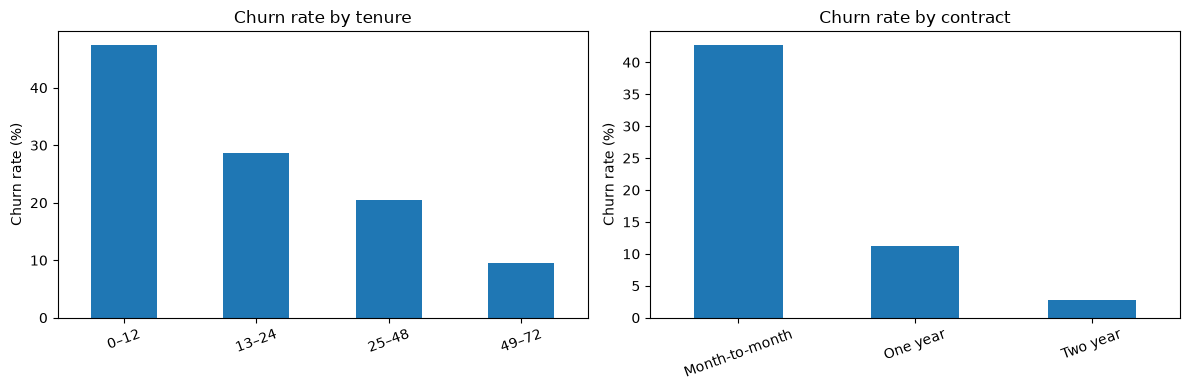

In [5]:
df['TenureGroup'] = pd.cut(df['tenure'], bins=[-1,12,24,48,72],
                           labels=['0–12','13–24','25–48','49–72'])
def churn_summary(group):
    tbl = df.groupby(group, observed=True)['Churn'].agg(
        customers='size', churned=lambda s: s.eq('Yes').sum())
    tbl['churn_rate'] = tbl['churned'] / tbl['customers']
    return tbl
by_tenure = churn_summary('TenureGroup')
by_contract = churn_summary('Contract')
display(by_tenure.style.format({'churn_rate':'{:.1%}'}))
display(by_contract.style.format({'churn_rate':'{:.1%}'}))
fig, axs = plt.subplots(1,2,figsize=(12,4))
by_tenure['churn_rate'].mul(100).plot.bar(ax=axs[0],title='Churn rate by tenure')
by_contract['churn_rate'].mul(100).plot.bar(ax=axs[1],title='Churn rate by contract')
for ax in axs:
    ax.set_ylabel('Churn rate (%)')
    ax.set_xlabel('')
    ax.tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.show()

## 4. Statistical association and effect size

In [6]:
table = pd.crosstab(df['Contract'], df['Churn'])
chi2, pvalue, dof, expected = chi2_contingency(table)
n_obs = table.to_numpy().sum()
v = np.sqrt(chi2 / (n_obs * min(table.shape[0]-1, table.shape[1]-1)))
p_month = df.loc[df['Contract'].eq('Month-to-month'), 'Churn'].eq('Yes').mean()
p_two = df.loc[df['Contract'].eq('Two year'), 'Churn'].eq('Yes').mean()
rd = p_month - p_two
rr = p_month / p_two
odds_ratio = (p_month/(1-p_month)) / (p_two/(1-p_two))
display(table)
print(f'Chi-square: {chi2:.3f}; df: {dof}; p: {pvalue:.3g}; Cramér V: {v:.3f}')
print(f'Monthly risk: {p_month:.1%}; Two-year risk: {p_two:.1%}')
print(f'Risk difference: {rd:.1%} (percentage-point difference); RR: {rr:.2f}; OR: {odds_ratio:.2f}')
assert (expected > 0).all()

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Chi-square: 1184.597; df: 2; p: 5.86e-258; Cramér V: 0.410
Monthly risk: 42.7%; Two-year risk: 2.8%
Risk difference: 39.9% (percentage-point difference); RR: 15.08; OR: 25.58


**Interpretation:** a small p-value supports association. Cramér's V describes association strength, not causal impact. Risk difference is in percentage points; relative risk and odds ratio are ratios and should not be conflated. Contract and tenure are correlated; raw group contrasts are not adjusted causal effects.

## 5. Train / validation / test design (60% / 20% / 20%)

In [7]:
X = df.drop(columns=['Churn','customerID','TenureGroup'])
y = df['Churn'].map({'No':0,'Yes':1}).astype(int)
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_development, y_development, test_size=0.25,
    stratify=y_development, random_state=RANDOM_STATE)
for name, yy in [('train',y_train),('validation',y_val),('test',y_test)]:
    print(name, len(yy),f'{yy.mean():.2%} churn')
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

train 4225 26.53% churn
validation 1409 26.54% churn
test 1409 26.54% churn


**Leakage rule:** Fit the preprocessor on the training set only. Choose the model, probability threshold, and retention policy using training/validation data. Use the test set **once** for final reporting; do not tune to test scores. If deploying to future months, replace random splits with a suitable time-aware design and check for temporal leakage.

## 6. Build preprocessing + model pipelines

In [8]:
numeric_features = ['tenure','MonthlyCharges','TotalCharges']
categorical_features = [c for c in X.columns if c not in numeric_features]
def make_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('imputer',SimpleImputer(strategy='median')),
                          ('scaler',StandardScaler())]), numeric_features),
        ('cat', Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                          ('encoder',OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
    ])
models = {
    'Logistic Regression': Pipeline([
        ('preprocess',make_preprocessor()),
        ('classifier',LogisticRegression(max_iter=2000,random_state=RANDOM_STATE))]),
    'Random Forest': Pipeline([
        ('preprocess',make_preprocessor()),
        ('classifier',RandomForestClassifier(n_estimators=250,min_samples_leaf=5,
                                            random_state=RANDOM_STATE,n_jobs=-1))])
}
print('Numerical:', numeric_features)
print('Categorical:',len(categorical_features))

Numerical: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: 16


## 7. Compare models using validation data

In [9]:
comparison = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_val)[:,1]
    comparison.append({'model':name,
                       'roc_auc':roc_auc_score(y_val,prob),
                       'pr_auc':average_precision_score(y_val,prob),
                       'brier':brier_score_loss(y_val,prob)})
score_df = pd.DataFrame(comparison).sort_values(['pr_auc','roc_auc'],ascending=False)
display(score_df.round(4))
selected_name = score_df.iloc[0]['model']
print('Selected using VALIDATION average precision:', selected_name)
chosen = models[selected_name]
val_proba = chosen.predict_proba(X_val)[:,1]

,model,roc_auc,pr_auc,brier
0,Logistic Regression,0.8360,0.6424,0.1381
1,Random Forest,0.8348,0.6344,0.1390


Selected using VALIDATION average precision: Logistic Regression


**Metric choices:** PR-AUC (average precision) is useful for churn targeting; ROC-AUC measures ranking; Brier score measures squared probability error. Choosing based on PR-AUC here is an explicit illustrative policy; calibration must also be checked before treating probabilities as financial inputs.

## 8. Threshold analysis on validation data

In [10]:
thresholds = np.arange(0.10, 0.91, 0.05)
rows=[]
for t in thresholds:
    yp = (val_proba >= t).astype(int)
    rows.append({'threshold':round(float(t),2),
                 'precision':precision_score(y_val,yp,zero_division=0),
                 'recall':recall_score(y_val,yp,zero_division=0),
                 'f1':f1_score(y_val,yp,zero_division=0),
                 'targeted':int(yp.sum())})
threshold_table=pd.DataFrame(rows)
display(threshold_table.round(3))
# Choose on validation, NEVER on final held-out test
best_threshold=float(threshold_table.loc[threshold_table['f1'].idxmax(),'threshold'])
print('Illustrative validation-selected F1 threshold:',best_threshold)

,threshold,precision,recall,f1,targeted
0,0.10,0.394,0.922,0.552,875
1,0.15,0.428,0.888,0.578,775
2,0.20,0.465,0.837,0.598,673
3,0.25,0.507,0.802,0.621,592
4,0.30,0.538,0.751,0.627,522
5,0.35,0.567,0.706,0.629,466
6,0.40,0.595,0.644,0.619,405
7,0.45,0.633,0.591,0.611,349
8,0.50,0.658,0.535,0.590,304
9,0.55,0.688,0.484,0.568,263


Illustrative validation-selected F1 threshold: 0.35


## 9. Final held-out test evaluation — no further tuning

,held-out test score
accuracy,0.7672
precision,0.5473
recall,0.7112
f1,0.6186
roc_auc,0.8430
pr_auc,0.6345
brier,0.1377


              precision    recall  f1-score   support

           0       0.88      0.79      0.83      1035
           1       0.55      0.71      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409



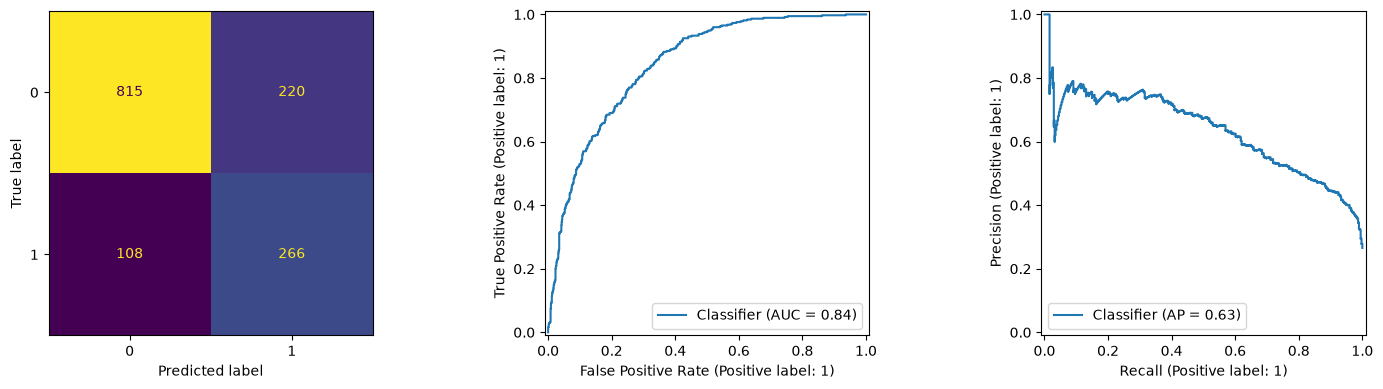

In [11]:
test_proba = chosen.predict_proba(X_test)[:,1]
test_pred = (test_proba >= best_threshold).astype(int)
final_metrics = pd.Series({
    'accuracy': accuracy_score(y_test,test_pred),
    'precision':precision_score(y_test,test_pred,zero_division=0),
    'recall':recall_score(y_test,test_pred,zero_division=0),
    'f1':f1_score(y_test,test_pred,zero_division=0),
    'roc_auc':roc_auc_score(y_test,test_proba),
    'pr_auc':average_precision_score(y_test,test_proba),
    'brier':brier_score_loss(y_test,test_proba)})
display(final_metrics.to_frame('held-out test score').round(4))
print(classification_report(y_test,test_pred,zero_division=0))
fig,axes=plt.subplots(1,3,figsize=(15,4))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,ax=axes[0],colorbar=False)
RocCurveDisplay.from_predictions(y_test,test_proba,ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test,test_proba,ax=axes[2])
plt.tight_layout();plt.show()

**Caution:** The test scores are valid only for this random split and this public demonstration dataset. They are not production guarantees. Calibration, time drift, fairness across segments, and privacy safeguards must be evaluated before real outreach.

## 10. Interpret logistic regression coefficients (optional explanatory baseline)

In [12]:
log_model=models['Logistic Regression']
enc_names=log_model.named_steps['preprocess'].get_feature_names_out()
coeffs=log_model.named_steps['classifier'].coef_.ravel()
coefs=pd.DataFrame({'feature':enc_names,'coefficient':coeffs,
                    'odds_multiplier':np.exp(coeffs)})
display(coefs.reindex(coefs.coefficient.abs().sort_values(ascending=False).index).head(15).round(3))

,feature,coefficient,odds_multiplier
0,num__tenure,-1.312,0.269
39,cat__Contract_Two year,-0.856,0.425
37,cat__Contract_Month-to-month,0.663,1.942
2,num__TotalCharges,0.592,1.808
16,cat__InternetService_DSL,-0.569,0.566
17,cat__InternetService_Fiber optic,0.537,1.710
1,num__MonthlyCharges,-0.333,0.717
13,cat__MultipleLines_No,-0.310,0.733
40,cat__PaperlessBilling_No,-0.294,0.745
10,cat__Dependents_Yes,-0.248,0.781


One-hot features here use `drop=None`, so category coefficients should **not** be interpreted as simple comparisons to a single reference category. Correlations, regularization, and scaling also affect coefficient interpretation. For a reference-category odds ratio, fit an explicitly defined contrast model.

## 11. Retention campaign simulation using validation data

### Explicit hypothetical assumptions

- Offer cost: **₹500 per targeted customer**.
- Incremental value of retaining a churner: **₹5,000**.
- Assumed **causal offer effectiveness** among would-be churners: **20%** (NOT estimable from this churn dataset).
- Campaign budget: **₹50,000** for this validation cohort.

Under simplified assumptions, expected net benefit for a targeted customer with calibrated churn probability `p` is `p × 0.20 × ₹5,000 − ₹500`. This is a **scenario**, not a measured return. A randomized controlled trial or credible uplift model is required to estimate causal effectiveness, and probability calibration must be verified.

In [13]:
OFFER_COST = 500.0
CUSTOMER_VALUE = 5000.0
ASSUMED_INCREMENTAL_EFFECT = 0.20
BUDGET = 50000.0
campaign = pd.DataFrame({
    'customerID': df.loc[X_val.index,'customerID'].to_numpy(),
    'churn_probability':val_proba,
    'actual_churn_for_validation_only':y_val.to_numpy()
})
campaign['expected_gross_benefit']=(campaign.churn_probability
                                   *ASSUMED_INCREMENTAL_EFFECT*CUSTOMER_VALUE)
campaign['expected_net_benefit']=campaign.expected_gross_benefit-OFFER_COST
break_even = OFFER_COST/(ASSUMED_INCREMENTAL_EFFECT*CUSTOMER_VALUE)
capacity = int(BUDGET//OFFER_COST)
# Equal per-customer costs => ranking by positive expected net benefit is optimal.
eligible = campaign.query('expected_net_benefit > 0').sort_values(
    'expected_net_benefit',ascending=False)
selected = eligible.head(capacity).copy()
print('Break-even probability:',f'{break_even:.1%}')
print('Budget capacity:',capacity)
print('Selected customers:',len(selected))
print('Offer spend:',f"₹{len(selected)*OFFER_COST:,.0f}")
print('Total modeled expected net benefit:',f"₹{selected.expected_net_benefit.sum():,.0f}")
display(selected[['customerID','churn_probability','expected_net_benefit']].head(10).round(2))

Break-even probability: 50.0%
Budget capacity: 100
Selected customers: 100
Offer spend: ₹50,000
Total modeled expected net benefit: ₹24,121


,customerID,churn_probability,expected_net_benefit
868,5567-WSELE,0.84,342.39
456,3049-SOLAY,0.83,326.44
584,4822-RVYBB,0.82,320.46
79,0781-LKXBR,0.82,316.55
230,2446-BEGGB,0.81,314.38
221,4695-WJZUE,0.81,313.02
29,3988-RQIXO,0.81,310.27
869,4912-PIGUY,0.81,310.20
346,3489-HHPFY,0.80,302.13
1222,6521-YYTYI,0.80,299.00


**Production rule:** do not use `actual_churn_for_validation_only` to target customers; it is included only for retrospective validation. This simulation uses validation probabilities to illustrate a policy. In deployment, train and calibrate on historical data, estimate heterogeneous treatment uplift experimentally, and calculate costs/benefits for the new eligible customer cohort. When offers have unequal costs, the problem becomes a knapsack/budget optimization problem rather than simple top-N ranking.

## 12. Portfolio-ready executive summary (auto-generated)

In [14]:
top_contract=by_contract['churn_rate'].idxmax()
print(f"""DATASET: {len(df):,} customers; churn rate {y.mean():.1%}.
ASSOCIATION: Highest observed contract-group churn rate: {top_contract}.
CHI-SQUARE: statistic={chi2:.1f}, p={pvalue:.2g}, Cramér's V={v:.3f}.
MODEL: {selected_name} (selected by validation PR-AUC).
HELD-OUT TEST: ROC-AUC={final_metrics['roc_auc']:.3f}, PR-AUC={final_metrics['pr_auc']:.3f},
  Precision={final_metrics['precision']:.3f}, Recall={final_metrics['recall']:.3f}, F1={final_metrics['f1']:.3f}.
HYPOTHETICAL CAMPAIGN: {len(selected)} selected; spend=₹{len(selected)*OFFER_COST:,.0f};
  modeled expected net benefit=₹{selected.expected_net_benefit.sum():,.0f}.
LIMITATION: No measured uplift or causal proof; business value is a scenario only.""")

DATASET: 7,043 customers; churn rate 26.5%.
ASSOCIATION: Highest observed contract-group churn rate: Month-to-month.
CHI-SQUARE: statistic=1184.6, p=5.9e-258, Cramér's V=0.410.
MODEL: Logistic Regression (selected by validation PR-AUC).
HELD-OUT TEST: ROC-AUC=0.843, PR-AUC=0.635,
  Precision=0.547, Recall=0.711, F1=0.619.
HYPOTHETICAL CAMPAIGN: 100 selected; spend=₹50,000;
  modeled expected net benefit=₹24,121.
LIMITATION: No measured uplift or causal proof; business value is a scenario only.


## 13. Reproducibility and next engineering steps

- Maintain the source CSV with attribution; do not present its simulated customers as live commercial records.
- Save this notebook and a pinned environment/lockfile; rerun top to bottom after each code change.
- Add unit tests for `TotalCharges` conversion, splitting, feature columns, and campaign budget logic.
- Export trained pipelines via `joblib` only after locking dependencies and assessing the risk of loading serialized artifacts from untrusted sources.
- For a deployable application: build `src/` preprocessing/training/evaluation modules, CLI commands, model card, data dictionary, and a Streamlit dashboard; add CI and data-drift monitoring.
- For genuine retention effectiveness and uplift modeling, obtain randomized offer/control outcomes, establish an experimental estimand, and evaluate the targeting policy out-of-sample.